# Notebook Tema 5 VA, Master IA UMU, curso 2026/2027
# _Transfer learning_ para reentrenar una CNN de detección de objetos propios

## Entorno e imports necesarios

Usamos el mismo entorno Python 3.11 de los notebooks anteriores, con PyTorch y
`requirements-yolo.txt`; véase `INSTALL.md`. En local no se instalan paquetes desde el notebook.
En Colab, el arranque instala únicamente los extras de Ultralytics/ONNX que falten,
reutilizando PyTorch y OpenCV del runtime.
En Colab se recomienda GPU. Conservamos YOLOv8n, las 600 imágenes generadas
(300/200/100 para train/validación/test) y las 10 épocas de entrenamiento.
Las descargas, datos generados, pesos y resultados quedan en `output/10_yolo/`.
VisDrone ocupa unos 1,45 GiB comprimido; la primera ejecución necesita espacio
y conexión a Internet. Las siguientes reutilizan las descargas y su extracción.


Usaremos la librería [ultralytics](https://github.com/ultralytics/ultralytics), que incorpora arquitecturas estado del arte en detección de objetos, segmentación, clasificación y estimación de _pose_, al tiempo que es muy sencilla de utilizar. Permite generar modelos reentrenados con _datasets_ propios con relativamente poco coste de entrenamiento, y exportarlos posteriormente a modelos altamente eficientes en inferencia (ONNX, TensorRT, etc.). También posibilita la interacción sencilla con otros modelos fundacionales más potentes, como SAM o RT-DETR, entre otros:

In [1]:
!date # Para medir el tiempo de ejecución de todo el notebook

mar 17 nov 2026 16:48:28 CET


In [2]:
import os
import sys
from pathlib import Path

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

OUTPUT_ROOT = (Path("10_yolo") if Path.cwd().name == "output" else Path("output/10_yolo")).resolve()
DOWNLOADS_DIR = OUTPUT_ROOT / "downloads"
DATASETS_DIR = OUTPUT_ROOT / "datasets"
RUNS_DIR = OUTPUT_ROOT / "runs"
for directory in (DOWNLOADS_DIR, DATASETS_DIR, RUNS_DIR):
    directory.mkdir(parents=True, exist_ok=True)
os.environ["YOLO_CONFIG_DIR"] = str(OUTPUT_ROOT / "config")
os.environ["YOLO_AUTOINSTALL"] = "false"

if IN_COLAB:
    import importlib.util
    import subprocess
    colab_extras = {
        "ultralytics": "ultralytics==8.4.178",
        "onnx": "onnx==1.23.2",
        "onnxruntime": "onnxruntime==1.31.0",
        "onnxslim": "onnxslim==0.1.98",
    }
    missing = [package for module, package in colab_extras.items()
               if importlib.util.find_spec(module) is None]
    if missing:
        subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
        importlib.invalidate_caches()


In [3]:
import glob
import random
import os
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import cv2
import shutil
import ipywidgets as widgets
import subprocess
import torch
import math

from pathlib import Path
import ultralytics
import ultralytics.utils as yolo_utils
from ultralytics import YOLO, settings
import yaml
import tarfile
import zipfile
from shutil import copyfileobj
from urllib.request import Request, urlopen
from IPython.display import display, Image
from ipywidgets import Output
from ultralytics.utils.plotting import Annotator, colors

settings.update({"datasets_dir": str(DATASETS_DIR), "weights_dir": str(DOWNLOADS_DIR),
                 "runs_dir": str(RUNS_DIR), "sync": False,
                 **{key: False for key in ("clearml", "comet", "dvc", "mlflow", "raytune", "tensorboard", "wandb")}})
# La comprobación AMP usa esta ruta, fijada por la librería al importarse.
yolo_utils.WEIGHTS_DIR = DOWNLOADS_DIR
DEVICE = 0 if torch.cuda.is_available() else "cpu"
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
print("Entorno:", "Google Colab" if IN_COLAB else "Jupyter local")
print("Python:", sys.version.split()[0], "Ultralytics:", ultralytics.__version__, "PyTorch:", torch.__version__)
print("Dispositivo:", torch.cuda.get_device_name(0) if DEVICE == 0 else "CPU")

Entorno: Jupyter local
Python: 3.11.9 Ultralytics: 8.4.178 PyTorch: 2.14.1+cu126
Dispositivo: NVIDIA GeForce RTX 3060


## Generación de un _dataset_ artificial, de tamaño controlado

Usaremos un procedimiento simple para generar un _dataset_ de prueba, con suficiente interés como para generar un problema de detección de objetos no trivial, no fácilmente resoluble con técnicas clásicas de visión, y que sin embargo se resuelve con relativa facilidad con una arquitectura CNN muy usada en OD, eficiente en GPUs convencionales e incluso en CPUs, YOLOv8 (2023). Reentrenaremos dicha red (mediante _transfer learning_, partiendo de unos pesos preentrenados para resolver un problema completamente diferente, en concreto el [_dataset_ COCO](https://cocodataset.org/) con nuestro propio _dataset_ del que podemos controlar tanto el número de imágenes de entrenamiento/test/validación, como el número de objetos por imagen.

### Descarga del _dataset_ de imágenes de _background_

Para dar variedad al conjunto de fondos utilizaremos el _dataset_ [VisDrone2019](https://arxiv.org/pdf/2001.06303.pdf) (en el enlace puede consultarse directamente el _paper_ en que se publicó, donde también pueden verse varias imágenes de ejemplo). El _dataset_ completo puede encontrarse en este enlace: [https://github.com/VisDrone/VisDrone-Dataset](https://github.com/VisDrone/VisDrone-Dataset). Nosotros descargaremos sólo el subconjunto de _training_ (que, con sus 6471 imágenes, es más que suficiente para nuestros experimentos):

In [4]:
def download_if_missing(url, destination, validator=None, minimum_size=1):
    destination = Path(destination)
    def valid(path):
        return (path.is_file() and path.stat().st_size >= minimum_size
                and (validator is None or validator(path)))
    if valid(destination):
        print(f"Ya existe: {destination.name}")
        return destination
    temporary = destination.with_suffix(destination.suffix + ".part")
    print(f"Descargando {destination.name}")
    try:
        request = Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urlopen(request, timeout=60) as response, temporary.open("wb") as output:
            copyfileobj(response, output)
        if not valid(temporary):
            raise RuntimeError(f"La descarga no contiene el archivo esperado: {url}")
        temporary.replace(destination)
    finally:
        temporary.unlink(missing_ok=True)
    return destination

VISDRONE_DIR = OUTPUT_ROOT / "VisDrone2019-DET-train"
VISDRONE_ZIP = download_if_missing(
    "https://github.com/ultralytics/yolov5/releases/download/v1.0/VisDrone2019-DET-train.zip",
    DOWNLOADS_DIR / "VisDrone2019-DET-train.zip", zipfile.is_zipfile, minimum_size=1_000_000)


Ya existe: VisDrone2019-DET-train.zip


In [5]:
if len(list((VISDRONE_DIR / "images").glob("*.jpg"))) != 6471:
    print("Descomprimiendo imágenes de fondo...")
    with zipfile.ZipFile(VISDRONE_ZIP) as archive:
        archive.extractall(OUTPUT_ROOT)
else:
    print("VisDrone ya extraído; se reutiliza.")
assert len(list((VISDRONE_DIR / "images").glob("*.jpg"))) == 6471
print("6471 imágenes de background disponibles")


VisDrone ya extraído; se reutiliza.
6471 imágenes de background disponibles


Mostramos p.e. la primera imagen (con su nombre, formato y resolución):

0000002_00005_d_0000014.jpg (540, 960, 3) uint8


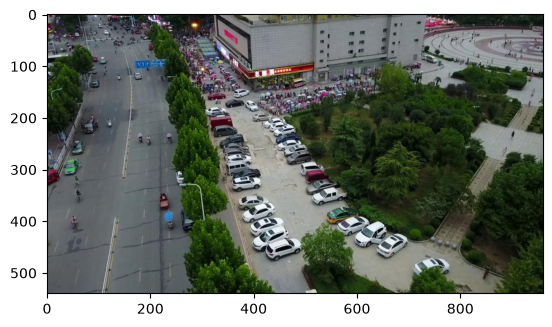

In [6]:
sample_background = VISDRONE_DIR / "images" / "0000002_00005_d_0000014.jpg"
image = cv2.imread(str(sample_background))
print(sample_background.name, image.shape, image.dtype)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB));


### Descarga del _dataset_ de imágenes para _foreground_

Para dar variedad al conjunto de objetos, usaremos el dataset ALOT ("Amsterdam Library of textures"), que puede encontrarse en este enlace: [https://aloi.science.uva.nl/public_alot/](https://aloi.science.uva.nl/public_alot/). Inicialmente, jugaremos sólo con 9 de las 250 texturas disponibles (si bien en los ejercicios se propondrá utilizar diferentes combinaciones de la totalidad de texturas, disponibles en el mismo URL, cambiando `alot9classes.tgz` por `alot250classes.tgz`):

In [7]:
# Reutiliza también el archivo del notebook 09 si ya se descargó allí.
ALOT_DIR = OUTPUT_ROOT / "alot9classes"
shared_archive = OUTPUT_ROOT.parent / "09_alot" / "alot9classes.tgz"
ALOT_ARCHIVE = shared_archive if shared_archive.is_file() else DOWNLOADS_DIR / "alot9classes.tgz"
ALOT_ARCHIVE = download_if_missing("https://ditec.um.es/~pedroe/alot9classes.tgz",
                                   ALOT_ARCHIVE, tarfile.is_tarfile, minimum_size=1_000_000)
# Para explorar las 250 texturas, adaptar el archivo y el directorio a alot250classes.


Ya existe: alot9classes.tgz


Usaremos, en particular, las nueve primeras clases del _dataset_ (etiquetas '1', ..., '9'), para cada una de las cuales se dispone de 100 imágenes (en su resolución más pequeña):

In [8]:
if not all(len(list((ALOT_DIR / str(label)).glob("*.png"))) == 100 for label in range(1, 10)):
    print("Descomprimiendo imágenes de texturas para objetos...")
    with tarfile.open(ALOT_ARCHIVE, "r:gz") as archive:
        archive.extractall(OUTPUT_ROOT, filter="data")
else:
    print("ALOT ya extraído; se reutiliza.")
assert all(len(list((ALOT_DIR / str(label)).glob("*.png"))) == 100 for label in range(1, 10))
print("900 imágenes de texturas disponibles")


ALOT ya extraído; se reutiliza.
900 imágenes de texturas disponibles


Mostramos también, p.e, la primera imagen, junto con su nombre y resolución:

1_c1i.png (256, 384, 3) uint8


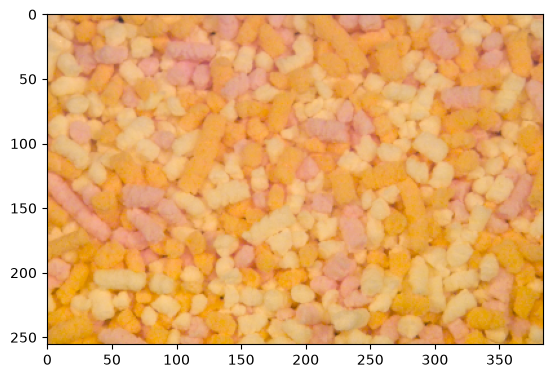

In [9]:
image = cv2.imread(str(ALOT_DIR / "1" / "1_c1i.png"))
print("1_c1i.png", image.shape, image.dtype)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB));


Mostramos ahora las primeras 10 imágenes por cada clase (en una fila por cada una de las 9 clases consideradas):


In [10]:
def read_images(pathname):
  path = Path(pathname)
  labels = sorted([l.name for l in path.iterdir()])
  imgs = []
  for classpath in [path / l for l in labels]:
    imgsclass = [cv2.cvtColor(cv2.imread(str(filepath)),cv2.COLOR_RGB2BGR) for filepath in sorted([p for p in classpath.iterdir()])]
    imgs.append(imgsclass)

  NC = len(imgs)                                 # Número de clases.
  NICs = [len(imgsclass) for imgsclass in imgs]  # Lista de número de imágenes por clase.
  NIs = sum(NICs)                                # Número total de imágenes.
  return imgs, labels, NC, NICs, NIs

imgs, labels, NC, NICs, NIs = read_images(ALOT_DIR)
print(f" Número total de clases: {NC}\n"
      f" Nümero total de imágenes: {NIs}\n"
      f" Número de imágenes por cada clase: ({[ (i,l+'/',ncs) for (i,l,ncs) in zip(range(len(labels)),labels,NICs)]})\n"
      f" Tipo de datos: {imgs[0][0].dtype}\n"
      f" Rango: [{np.min([np.min(img) for imgsclass in imgs for img in imgsclass])},{np.max([np.max(img) for imgsclass in imgs for img in imgsclass])}]")

 Número total de clases: 9
 Nümero total de imágenes: 900
 Número de imágenes por cada clase: ([(0, '1/', 100), (1, '2/', 100), (2, '3/', 100), (3, '4/', 100), (4, '5/', 100), (5, '6/', 100), (6, '7/', 100), (7, '8/', 100), (8, '9/', 100)])
 Tipo de datos: uint8
 Rango: [0,254]


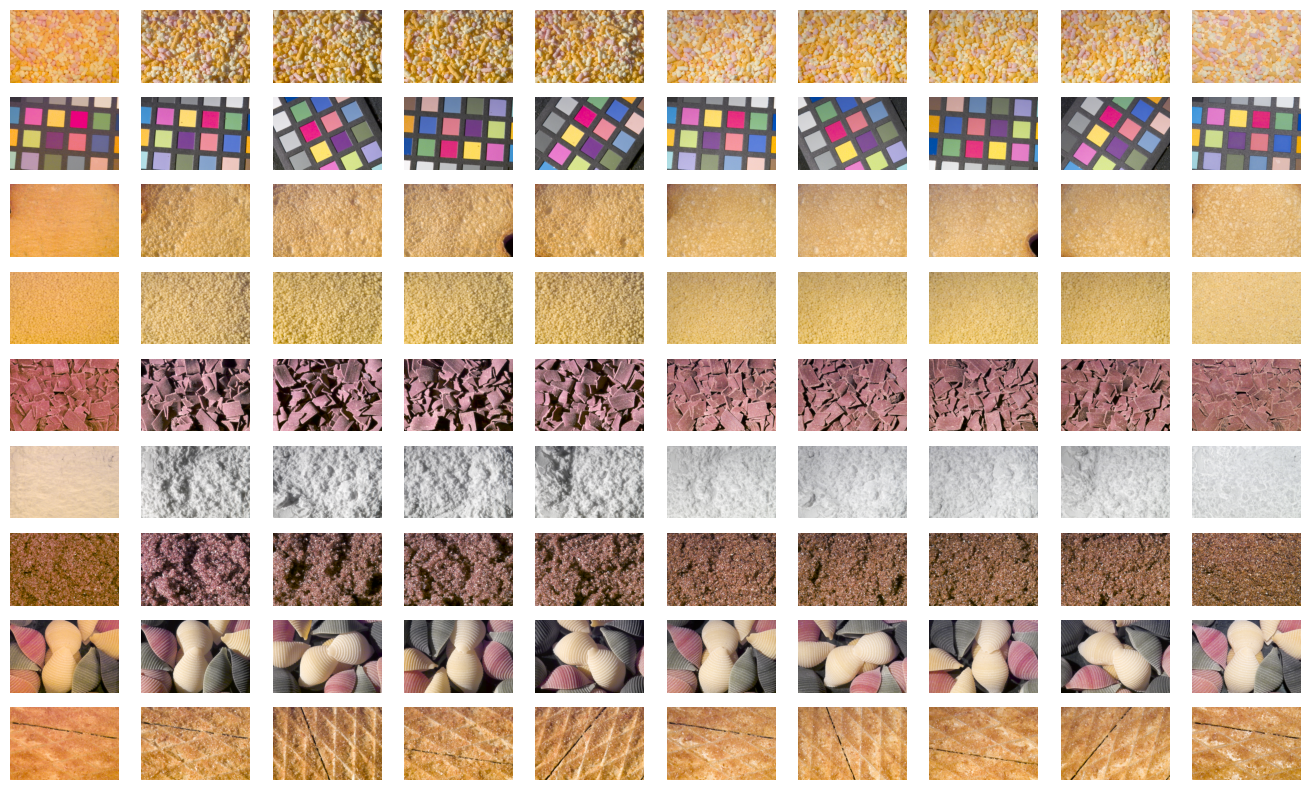

In [11]:
def plot_imgs(imgs, n_imgs_per_class=5, title=""):
  assert n_imgs_per_class>=2, "n_imgs_per_class debe ser >=2 en función plot_imgs"
  rows, cols = imgs[0][0].shape[:2]
  aspect_ratio = (rows*NC) / (cols*n_imgs_per_class)
  fig, axs, = plt.subplots(NC, n_imgs_per_class, figsize=(10.0/aspect_ratio, 10.0),sharex=True, sharey=True)
  for r in range(NC):
    for c in range(n_imgs_per_class):
      axs[r,c].imshow(imgs[r][c], cmap="gray")
      axs[r,c].axis("off")
  if(title != ""):
    fig.suptitle(title, fontsize=20, y=0.925)

plot_imgs(imgs, 10)

### Generación de "objetos"

Creamos una función auxiliar, `random_object(...)`, que toma aleatoriamente una imagen de una de las clases, y coge de ella una cierta elipse, de tamaño y rotación también aleatorios (dentro de unos márgenes). La elipse tomada será un "objeto generado aleatorio" de la clase en cuestión:

In [12]:
def random_object(imgs, labels, imgs_per_class, marginratio=0.3, minaspectratioellipse=0.5):
    def crop_non_black(image):
        # Filas y columnas donde hay al menos un píxel que no es negro:
        active_rows = np.nonzero(np.any(image, axis=1))[0]
        active_cols = np.nonzero(np.any(image, axis=0))[0]
        y_min, y_max = active_rows[0], active_rows[-1]
        x_min, x_max = active_cols[0], active_cols[-1]
        cropped_image = image[y_min:y_max+1, x_min:x_max+1]
        return cropped_image
    cl = int(random.choice(labels))
    ind_img = random.randint(0,imgs_per_class[cl-1]-1)
    image = imgs[cl-1][ind_img]
    H,W,_ = image.shape
    margin = int(min(H,W)*marginratio)
    mask = np.zeros((H, W, 3), dtype=np.uint8)
    center = (random.randint(margin, W-margin), random.randint(margin, H-margin))
    maxaxes = min(abs(center[0]-0), abs(center[0]-W),
                  abs(center[1]-0), abs(center[1]-H))
    axesx = random.randint(maxaxes//2, maxaxes)
    axesy = int(axesx*(minaspectratioellipse+(1.0-minaspectratioellipse)*random.random()))
    axes = (axesx, axesy)
    angle = random.randint(0, 359)
    mask = cv2.ellipse(mask, center, axes, angle, 0, 360, color=(255,255,255), thickness=-1)
    ellipse_img = np.where(mask, image, np.zeros_like(image))
    # plt.imshow(ellipse_img);
    return crop_non_black(ellipse_img), cl

Mostramos diez de estos objetos de ejemplo:

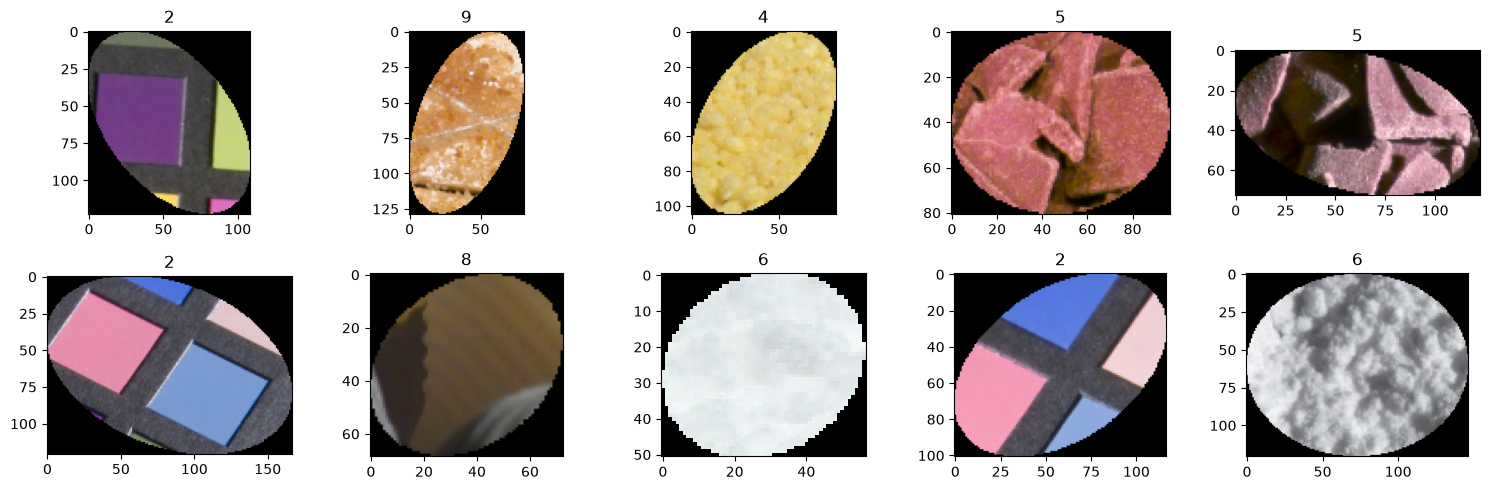

In [13]:

fig, axes = plt.subplots(2, 5, figsize=(15,5))
for i, ax in enumerate(axes.flat):
    fg_image, cl = random_object(imgs, labels, NICs)
    ax.imshow(fg_image, cmap='gray')
    ax.set_title(f"{cl}")
plt.tight_layout()
plt.show()

### Generación de fondos

Una función similar, `random_background_image(...)`, tomará una imagen aleatoria del conjunto de posibles fondos:

In [14]:
def random_background_image(directory, minh, minw, maxh, maxw):
    archivos_jpg = glob.glob(os.path.join(directory, '') + '*.jpg')
    image_path = random.choice(archivos_jpg)
    image = cv2.cvtColor(cv2.imread(image_path),cv2.COLOR_RGB2BGR)
    h, w, _ = image.shape
    start_x = np.random.randint(0, w - minw + 1)
    start_y = np.random.randint(0, h - minh + 1)
    end_x = start_x + np.random.randint(minw, min(w - start_x + 1, maxw))
    end_y = start_y + np.random.randint(minh, min(h - start_y + 1, maxh))
    cropped_image = image[start_y:end_y, start_x:end_x]
    return cropped_image

Mostramos aquí también otras ocho imágenes de ejemplo de estos fondos:

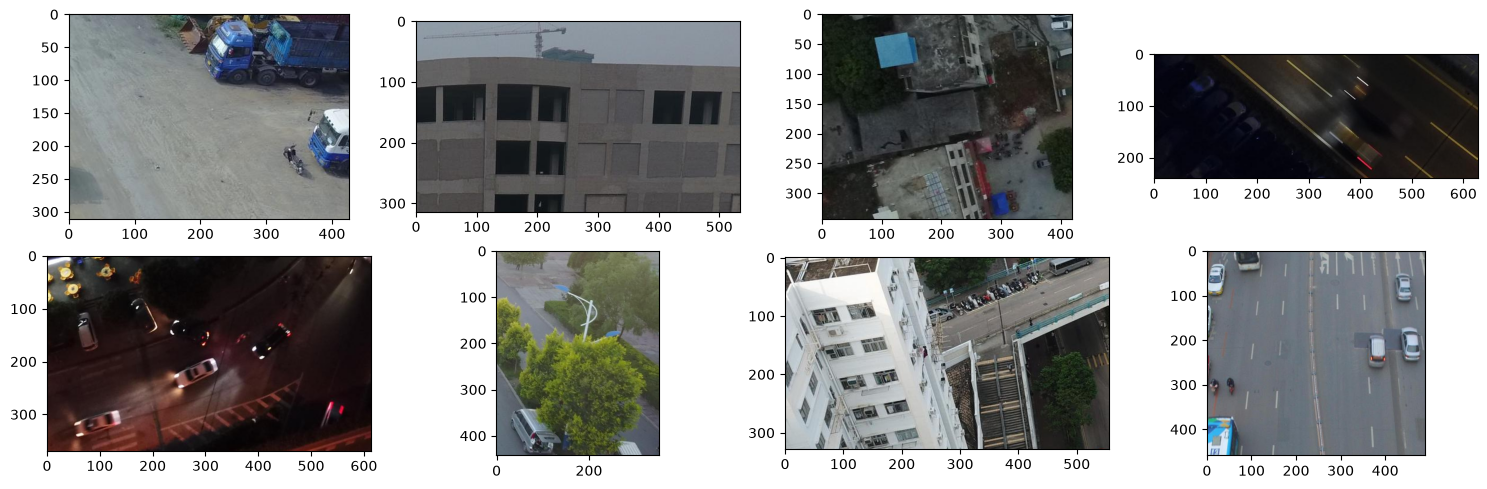

In [15]:
PATH_BG_IMGS = str(VISDRONE_DIR / "images")
fig, axes = plt.subplots(2, 4, figsize=(15,5))
for i, ax in enumerate(axes.flat):
    bg_image = random_background_image(PATH_BG_IMGS, 240, 320, 480, 640)
    ax.imshow(bg_image)
    #ax.axis('off')
plt.tight_layout()
plt.show()

### Generación de imágenes de muestra aleatorias

Generamos ahora, mediante la función `full_random_example(...)`, imágenes de muestra completas, con un número aleatorio de objetos encima de un cierto fondo, sin intentar evitar posibles solapamientos, y difuminando ligeramente los bordes de los objetos para realizar la fusión de forma menos abrupta:

In [16]:
def full_random_example(directory_bg, minh, minw, maxh, maxw,
                        imgs_obj, labels_obj, NICs_obj,
                        max_objs):
    def add_random_object(bg_image, obj_image):
        H,W,_ = bg_image.shape
        h,w,_ = obj_image.shape
        fg_mask = (obj_image!=0)
        start_x = np.random.randint(0, W - w + 1)
        start_y = np.random.randint(0, H - h + 1)
        bg_mask = np.zeros(bg_image.shape,dtype=bool)
        bg_mask[start_y:start_y+h,start_x:start_x+w] = fg_mask
        fg_image = np.zeros_like(bg_image)
        fg_image[start_y:start_y+h,start_x:start_x+w] = obj_image
        ncx, ncy, nw, nh = (start_x+w//2)/W, (start_y+h//2)/H, w/W, h/H
        bg_mask_float = bg_mask.astype(float)
        bg_mask_float = cv2.GaussianBlur(bg_mask_float,(35,35),35.0)
        bg_mask_float[bg_mask_float<0.5] = 0.0
        return (bg_mask_float*fg_image+(1.0-bg_mask_float)*bg_image).astype("uint8"), ncx, ncy, nw, nh
    bg_img = random_background_image(directory_bg, minh, minw, maxh, maxw)
    num_objs = random.randint(1,max_objs)
    out_rects = []
    final_img = bg_img
    for i in range(num_objs):
        obj_img, cl = random_object(imgs_obj, labels_obj, NICs_obj)
        final_img, ncx, ncy, nw, nh = add_random_object(final_img, obj_img)
        out_rects.append((cl,(ncx,ncy,nw,nh)))
    return final_img, out_rects

Mostramos 8 muestras de imágenes de ejemplo generadas de esta forma:

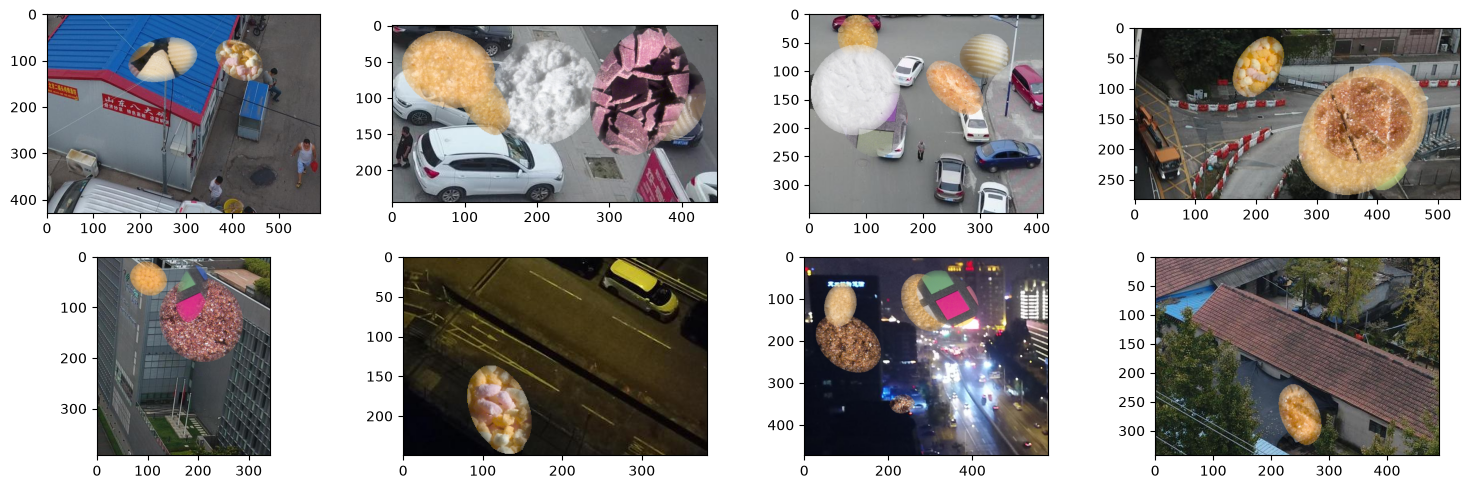

In [17]:
l_imgout, l_outrects = [], []
fig, axes = plt.subplots(2, 4, figsize=(15,5))
for i, ax in enumerate(axes.flat):
    imgout, outrects = full_random_example(PATH_BG_IMGS, 240, 320, 480, 640, imgs, labels, NICs, 5)
    l_imgout.append(imgout)
    l_outrects.append(outrects)
    ax.imshow(imgout)
    #ax.axis('off')
plt.tight_layout()
plt.show()

Dado que dichas muestras de imágenes con los "objetos" aleatorios han sido generadas de forma controlada, sabemos de antemano los _bounding boxes_ de dichos objetos (_"ground truth"_), que podremos usar tanto para el entrenamiento como para la validación y el posterior test. He aquí la función `draw_labeled_example(...)` para mostrar una imagen con el correspondiente etiquetado mediante _bounding boxes_:

In [18]:
def draw_labeled_example(imgout, out_rects, COLORS):
    def draw_rect(image, ncx, ncy, nw, nh, color=(255,255,255)):
        H,W,_ = image.shape
        x, y, w, h = int(ncx * W), int(ncy * H), int(nw * W), int(nh * H)
        imgout = cv2.rectangle(image, (x-w//2, y-h//2), (x+w//2, y+h//2), color, thickness=2)
        return imgout
    imgdraw = imgout
    for (cl,(ncx, ncy, nw, nh)) in out_rects:
        imgdraw = draw_rect(imgdraw, ncx, ncy, nw, nh, COLORS[cl-1])
    return imgdraw

Y he aquí las mismas 8 imágenes anteriores, en este caso mostradas con sus correspondientes etiquetados (cada color de caja se corresponde con una clase diferente):

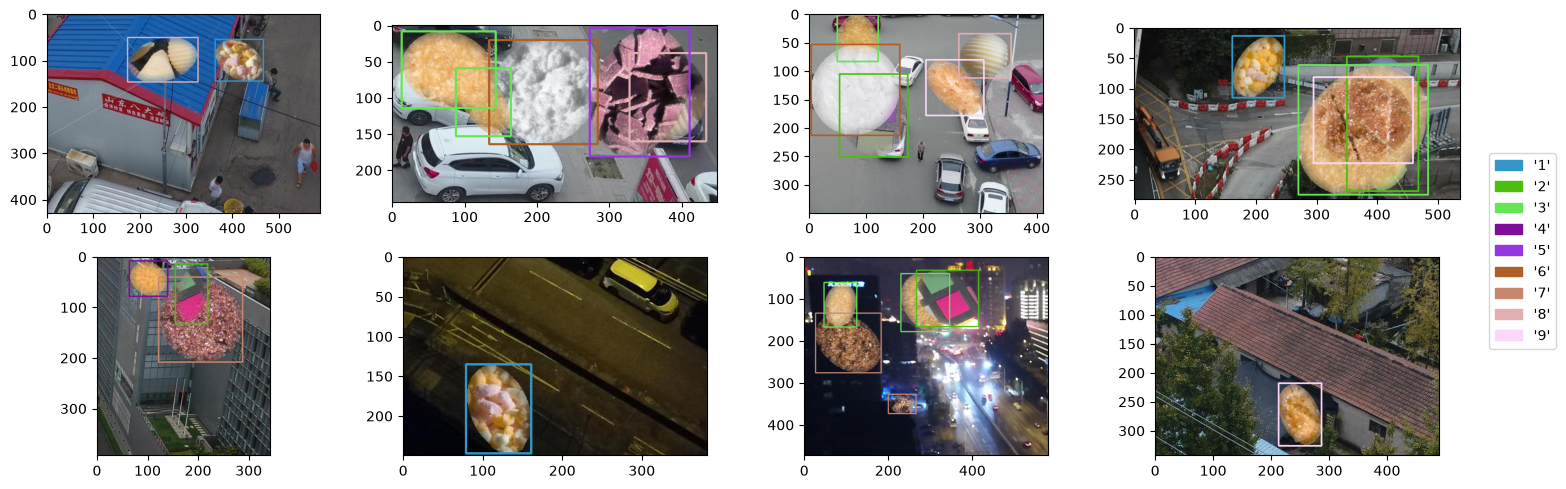

In [19]:
COLORS = [((25*i+50)%256, (40*i+150)%256, (70*i+200)%256) for i in range(NC)]
fig, axes = plt.subplots(2, 4, figsize=(15,5))
for i, ax in enumerate(axes.flat):
    imgout = draw_labeled_example(l_imgout[i], l_outrects[i], COLORS)
    ax.imshow(imgout)
    #ax.axis('off')
plt.tight_layout()

# Leyenda:
patches = []
for i, color in enumerate(COLORS, start=1):
    patch = mpatches.Patch(color=[c/255 for c in color], label=f"'{i}'")
    patches.append(patch)
plt.legend(handles=patches,  bbox_to_anchor=(1.15, 0.5), loc='lower left')
plt.show()

### Generación de un dataset completo

Generamos ahora un dataset completo, con el número deseado de imágenes de train, de validación, y de test:



In [20]:
def generate_dataset(name,
                     directory_bg, minh, minw, maxh, maxw,
                     imgs_obj, labels_obj, NICs_obj,
                     max_objs,
                     n_imgs_train, n_imgs_val, n_imgs_test):
    if not name or Path(name).name != name:
        raise ValueError("El nombre del dataset debe ser un nombre de directorio simple.")
    dataset_path = DATASETS_DIR / name
    if dataset_path.exists():
        shutil.rmtree(dataset_path)  # Solo regenera este dataset artificial, no las descargas.
    for split in ("train", "val", "test"):
        (dataset_path / "images" / split).mkdir(parents=True)
        (dataset_path / "labels" / split).mkdir(parents=True)
    config = {"path": str(dataset_path), "train": "images/train", "val": "images/val", "test": "images/test",
              "names": dict(enumerate(["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]))}
    yaml_path = dataset_path / f"{name}.yaml"
    with yaml_path.open("w") as file:
        yaml.safe_dump(config, file, sort_keys=False)
    for i in range(n_imgs_train+n_imgs_val+n_imgs_test):
        imgout, out_objs = full_random_example(directory_bg, minh, minw, maxh, maxw,
                                               imgs_obj, labels_obj, NICs_obj,
                                               max_objs)
        if i < n_imgs_train:
            basenameimgs = str(dataset_path / "images" / "train") + "/"
            basenamelabels = str(dataset_path / "labels" / "train") + "/"
        elif n_imgs_train <= i < n_imgs_train + n_imgs_val:
            basenameimgs = str(dataset_path / "images" / "val") + "/"
            basenamelabels = str(dataset_path / "labels" / "val") + "/"
        else:
            basenameimgs = str(dataset_path / "images" / "test") + "/"
            basenamelabels = str(dataset_path / "labels" / "test") + "/"
        cv2.imwrite(f"{basenameimgs}/img{i+1:06d}.jpg", cv2.cvtColor(imgout,cv2.COLOR_RGB2BGR))
        with open(f"{basenamelabels}/img{i+1:06d}.txt", 'w') as file:
            for (cls, (ncx, ncy, nw, nh)) in out_objs:
                file.write(f"{cls} {ncx:.4f} {ncy:.4f} {nw:.4f} {nh:.4f}" + '\n')

    return yaml_path

DATASET_YAML = generate_dataset("OD_ALOT_9C_300I", PATH_BG_IMGS, 240, 320, 480, 640, imgs, labels, NICs, 2, 300, 200, 100)

# Nota: si quisiésemos generar un dataset con, p.e., sólo objetos de una clase, y 100 imágenes de training:
# generate_dataset("OD_ALOT_1C_100I", PATH_BG_IMGS, 240, 320, 480, 640, imgs[:1], labels[:1], NICs[:1], 2, 100, 70, 50)

## Entrenamiento con el dataset generado

In [21]:
# Comenzamos con el mismo modelo preentrenado YOLOv8n.
YOLOV8_WEIGHTS = download_if_missing(
    "https://github.com/ultralytics/assets/releases/download/v8.3.0/yolov8n.pt",
    DOWNLOADS_DIR / "yolov8n.pt", zipfile.is_zipfile, minimum_size=1_000_000)
model = YOLO(str(YOLOV8_WEIGHTS))
# Y hacemos fine-tuning durante las 10 épocas originales con el dataset reducido.
results = model.train(data=str(DATASET_YAML), epochs=20, workers=0,
                      device=DEVICE, project=str(RUNS_DIR / "detect"), conf=0.25)


Ya existe: yolov8n.pt
New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.178 🚀 Python-3.11.9 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3060, 11887MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=0.25, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/pedroe/rsyncdir/repositorios/va-master.git/practicas/notebooks/output/10_yolo/datasets/OD_ALOT_9C_300I/OD_ALOT_9C_300I.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=

## Resultados del aprendizaje

Los resultados se generan en un subdirectorio de `output/10_yolo/runs/`, nuevo en cada ejecución:

In [22]:
print(results.save_dir)

/home/pedroe/rsyncdir/repositorios/va-master.git/practicas/notebooks/output/10_yolo/runs/detect/train


En realidad, la variable `results` devuelta por el entrenamiento del modelo tiene bastantes campos de interés que se pueden consultar:

In [23]:
list(filter(lambda x: x.strip("__")==x, dir(results)))

['ap_class_index',
 'box',
 'class_result',
 'clear_image_metrics',
 'clear_stats',
 'confusion_matrix',
 'curves',
 'curves_results',
 'fitness',
 'keys',
 'maps',
 'mean_results',
 'names',
 'nt_per_class',
 'nt_per_image',
 'process',
 'results_dict',
 'save_dir',
 'speed',
 'stats',
 'summary',
 'to_csv',
 'to_df',
 'to_json',
 'update_stats']

In [24]:
results.confusion_matrix.print()

0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0
0.0 32.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 1.0
0.0 0.0 35.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0
0.0 0.0 0.0 31.0 3.0 0.0 1.0 0.0 1.0 2.0 2.0
0.0 0.0 0.0 0.0 27.0 0.0 0.0 0.0 1.0 0.0 1.0
0.0 0.0 0.0 0.0 0.0 32.0 0.0 0.0 1.0 0.0 0.0
0.0 0.0 0.0 0.0 0.0 0.0 25.0 0.0 0.0 0.0 2.0
0.0 0.0 0.0 0.0 0.0 0.0 0.0 32.0 0.0 0.0 1.0
0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 26.0 0.0 5.0
0.0 1.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 31.0 2.0
0.0 0.0 0.0 1.0 1.0 0.0 4.0 1.0 0.0 1.0 0.0


Aunque una manera muy cómoda de comprobar los resultados es, directamente, inspeccionar las imágenes generadas dentro del directorio `results.saved_dir`. La siguiente celda permite inspeccionar las diferentes imágenes de salida proporcionadas (seleccionándolas en el correspondiente menú _dropdown_:

In [25]:
directory_path = results.save_dir
image_files = [file for file in os.listdir(directory_path) if file.endswith(('.png', '.jpg', '.jpeg'))]
dropdown = widgets.Dropdown(
    options=image_files,
    description='Selecciona una imagen:',
    disabled=False)

# Crea un widget de salida para mostrar las imágenes
output_image = Output()

# Función para mostrar la imagen seleccionada
def show_image(change):
    with output_image:
        output_image.clear_output()
        display(Image(filename=os.path.join(directory_path, change['new'])))

# Llama a show_image cuando el valor del dropdown cambie
dropdown.observe(show_image, names='value')

# Muestra el dropdown y el widget de salida
display(dropdown)
display(output_image)

Dropdown(description='Selecciona una imagen:', options=('labels.jpg', 'BoxPR_curve.png', 'train_batch190.jpg',…

Output()

De particular interés son:
* La evolución de las funciones de pérdida, y las métricas durante las épocas de entrenamiento.
* La matriz de confusión resultante (normalizada y sin normalizar).
* La curva de _precision vs. recall_ (PR).
* La comparación en un _batch_ cualquiera de validación del etiquetado original frente a la salida obtenida por el modelo entrenado.

## Salvado del modelo

Tras un entrenamiento, el modelo entrenado siempre queda disponible bajo el directorio generado `output/10_yolo/runs/detect/`, de modo que en posteriores ejecuciones del notebook podemos cargarlo directamente y ahorrarnos el tener que entrenarlo de nuevo:

In [26]:
saved_model_path = Path(model.ckpt_path)
print(f"{saved_model_path}: {saved_model_path.stat().st_size / 1024**2:.1f} MiB")


/home/pedroe/rsyncdir/repositorios/va-master.git/practicas/notebooks/output/10_yolo/downloads/yolov8n.pt: 6.2 MiB


## Descarga de un modelo ya entrenado

Descargamos un modelo ya entrenado con anterioridad...

In [27]:
SAVED_MODEL_URL = "https://ditec.um.es/~pedroe/OD_ALOT_9C_saved_in_server.pt"
SAVED_MODEL_PATH = download_if_missing(SAVED_MODEL_URL, DOWNLOADS_DIR / "OD_ALOT_9C_saved_in_server.pt",
                                       zipfile.is_zipfile, minimum_size=1_000_000)
print(f"{SAVED_MODEL_PATH.name}: {SAVED_MODEL_PATH.stat().st_size / 1024**2:.1f} MiB")


Ya existe: OD_ALOT_9C_saved_in_server.pt
OD_ALOT_9C_saved_in_server.pt: 6.0 MiB


... Y lo cargamos en la variable `model`, imprimiendo algunos de sus atributos más importantes:

In [28]:
model = YOLO(str(SAVED_MODEL_PATH))
print(f"Clases detectables por el modelo {model.ckpt_path} (de tipo {model.task}):\n   {model.names} ")
print(f"\nOtros datos de interés del modelo:\n   {model.overrides}")
print(f"\nEstructura de capas del modelo:")
print(model.info(detailed=True,verbose=True))

Clases detectables por el modelo /home/pedroe/rsyncdir/repositorios/va-master.git/practicas/notebooks/output/10_yolo/downloads/OD_ALOT_9C_saved_in_server.pt (de tipo detect):
   {0: 'zero', 1: 'one', 2: 'two', 3: 'three', 4: 'four', 5: 'five', 6: 'six', 7: 'seven', 8: 'eight', 9: 'nine'} 

Otros datos de interés del modelo:
   {'task': 'detect', 'data': 'datasets/OD_ALOT_9C_300I/OD_ALOT_9C_300I.yaml', 'imgsz': 640, 'single_cls': False, 'model': '/home/pedroe/rsyncdir/repositorios/va-master.git/practicas/notebooks/output/10_yolo/downloads/OD_ALOT_9C_saved_in_server.pt'}

Estructura de capas del modelo:
layer                                    name                type  gradient  parameters               shape        mu     sigma
    0                     model.0.conv.weight              Conv2d     False         432       [16, 3, 3, 3]  -0.00239     0.152        float32
    1                       model.0.bn.weight         BatchNorm2d     False          16                [16]      2.97   

## Exportación del modelo

En cualquier momento, podemos exportar el modelo en otros formatos . Dicha exportación permite su ejecución para inferencia en diferentes _backends_ (Nvidia TensorRT, torchscript, Keras, TensorFlow, ...). P.e., en este caso lo exportaremos el formato portable [ONNX](https://onnx.ai/) (Open Neural Network eXchange), que, entre otras cosas, nos permite la visualización gráfica de su  estructura de capas (algo muy interesante en este caso, ya que YOLOv8 es una arquitectura estado del arte en detección de objetos, muy optimizada en número de parámetros, pero a cambio, ¡bastante compleja en lo que a estructura se refiere!):

In [29]:
onnx_path = Path(model.export(format="onnx", device="cpu"))
assert onnx_path.is_file(), "No se ha generado el archivo ONNX."
print(onnx_path)


Ultralytics 8.4.178 🚀 Python-3.11.9 torch-2.14.1+cu126 CPU (12th Gen Intel Core i7-12700K)
Model summary (fused): 72 layers, 3,007,598 parameters, 0 gradients, 8.1 GFLOPs

PyTorch: starting from '/home/pedroe/rsyncdir/repositorios/va-master.git/practicas/notebooks/output/10_yolo/downloads/OD_ALOT_9C_saved_in_server.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 14, 8400) (6.0 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 0.5s, saved as '/home/pedroe/rsyncdir/repositorios/va-master.git/practicas/notebooks/output/10_yolo/downloads/OD_ALOT_9C_saved_in_server.onnx' (11.7 MB)

Export complete (0.6s)
Results saved to /home/pedroe/rsyncdir/repositorios/va-master.git/practicas/notebooks/output/10_yolo/downloads/OD_ALOT_9C_saved_in_server.onnx
Predict:         yolo predict task=detect model=/home/pedroe/rsyncdir/repositorios/va-master.git/practicas/notebooks/output/10_yolo/downloads/OD_ALOT_9C_saved_in_s

(En este punto, se recomienda descargar el archivo .onnx generado, y subirlo a la URL indicada (https://netron.app), para poder realizar la mencionada inspección gráfica del modelo).

## Inferencia

Descargamos ahora tanto un vídeo como una imagen independiente, para realizar pruebas varias de inferencia con el modelo entrenado:

In [30]:
def valid_video(path):
    cap = cv2.VideoCapture(str(path))
    try:
        ok, frame = cap.read()
        return ok and frame is not None
    finally:
        cap.release()

TEST_VIDEO_URL = "https://ditec.um.es/~pedroe/testvideo.mp4"
TEST_IMAGE_URL = "https://ditec.um.es/~pedroe/testimage.jpg"
TEST_VIDEO_PATH = download_if_missing(TEST_VIDEO_URL, DOWNLOADS_DIR / "testvideo.mp4", valid_video)
TEST_IMAGE_PATH = download_if_missing(TEST_IMAGE_URL, DOWNLOADS_DIR / "testimage.jpg",
                                      lambda path: cv2.imread(str(path)) is not None)


Ya existe: testvideo.mp4
Ya existe: testimage.jpg


Ultralytics nos permite realizar inferencia sobre una imagen de modo extremadamente sencillo, y siempre se puede acceder tanto a los _bounding_boxes_ de los objetos generados como a sus clases y confianzas, todo ellos en los atributos correspondiente del campo `boxes`:

In [31]:
testimg = cv2.cvtColor(cv2.imread(str(TEST_IMAGE_PATH)),cv2.COLOR_RGB2BGR)
results = model(testimg)
boxes = results[0].boxes.xyxy.cpu().tolist()
classes = results[0].boxes.cls.cpu().tolist()
print(results[0].boxes)


0: 544x640 1 two, 1 seven, 2.7ms
Speed: 0.9ms preprocess, 2.7ms inference, 0.5ms postprocess per image at shape (1, 3, 544, 640)
ultralytics.engine.results.Boxes object with attributes:

cls: tensor([2., 7.], device='cuda:0')
conf: tensor([0.9975, 0.9867], device='cuda:0')
data: tensor([[334.3496,  48.2349, 410.9397, 142.7387,   0.9975,   2.0000],
        [ 59.6504, 134.4638, 201.2515, 248.0361,   0.9867,   7.0000]], device='cuda:0')
id: None
is_track: False
orig_shape: (355, 439)
shape: torch.Size([2, 6])
xywh: tensor([[372.6447,  95.4868,  76.5901,  94.5037],
        [130.4510, 191.2499, 141.6011, 113.5722]], device='cuda:0')
xywhn: tensor([[0.8488, 0.2690, 0.1745, 0.2662],
        [0.2972, 0.5387, 0.3226, 0.3199]], device='cuda:0')
xyxy: tensor([[334.3496,  48.2349, 410.9397, 142.7387],
        [ 59.6504, 134.4638, 201.2515, 248.0361]], device='cuda:0')
xyxyn: tensor([[0.7616, 0.1359, 0.9361, 0.4021],
        [0.1359, 0.3788, 0.4584, 0.6987]], device='cuda:0')


Mostramos la imagen de test anotada con las correspondientes _bounding boxes_ y nombres de clases, usando la cómoda clase `Annotator` para ello:

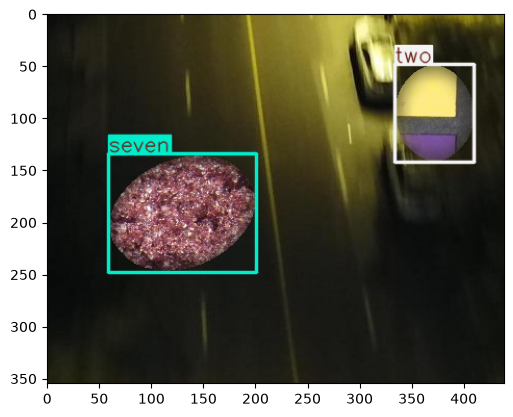

In [32]:
annotator = Annotator(testimg, line_width=2, example=model.names[0])
if boxes is not None:
    for box, cls in zip(boxes, classes):
        annotator.box_label(box, color=colors(int(cls), True), label=model.names[int(cls)])
plt.imshow(testimg);

### Visualización de los tensores de salida del modelo

No obstante, aunque lo anterior es muy cómodo para trabajar en inferencia, sigue siendo muy instructivo poder acceder directamente a los tensores de salida del modelo durante la inferencia sobre una imagen determinada. Para ello, intervendremos en las capas finales de dicha inferencia, para obtener los mencionados tensores de salida "crudos" (_raw_), y mostrarlos gráficamente para realizar la debida interpretación.

Para ello, en primer lugar intervenimos al modelo, añadiendo un _"forward hook"_ (función de _callback_ que se ejecuta al llegar a la ejecución de una capa determinada del modelo) a las cabezas finales (de regresión de _bounding boxes_ y de confianza de las clases) del modelo. La función de callback simplemente guardará los tensores respectivos de dichas capas en variables globales, que recuperará después para devolverlas al usuario de la función `get_results_and_output_tensors`:

In [33]:
first_output_tensor = None
second_output_tensor = None
third_output_tensor = None
fourth_output_tensor = None

def first_hook_function(module, input, output):
  global first_output_tensor
  first_output_tensor = output[0]

def second_hook_function(module, input, output):
  global second_output_tensor
  second_output_tensor = output[0]

def third_hook_function(module, input, output):
  global third_output_tensor
  third_output_tensor = output[0]

def fourth_hook_function(module, input, output):
  global fourth_output_tensor
  fourth_output_tensor = output[0]

# Los hooks deben conectarse al modelo que usa realmente el predictor.
detection_head = model.predictor.model.model.model[-1]
first_last_layer = detection_head.cv3[2][2]
second_last_layer = detection_head.cv3[1][2]
third_last_layer = detection_head.cv3[0][2]
fourth_last_layer = detection_head.dfl.conv

first_last_layer._forward_hooks.clear()
first_last_layer.register_forward_hook(first_hook_function)
second_last_layer._forward_hooks.clear()
second_last_layer.register_forward_hook(second_hook_function)
third_last_layer._forward_hooks.clear()
third_last_layer.register_forward_hook(third_hook_function)
fourth_last_layer._forward_hooks.clear()
fourth_last_layer.register_forward_hook(fourth_hook_function)

print("Última capa de procesamiento (cabeza que calcula confianza de clases, escala 1):\n  ", first_last_layer)
print("   Hooks de la capa: ", list(first_last_layer._forward_hooks.items()))
print("Última capa de procesamiento (cabeza que calcula confianza de clases, escala 2):\n  ", second_last_layer)
print("   Hooks de la capa: ", list(second_last_layer._forward_hooks.items()))
print("Última capa de procesamiento (cabeza que calcula confianza de clases, escala 3):\n  ", third_last_layer)
print("   Hooks de la capa: ", list(third_last_layer._forward_hooks.items()))
print("Última capa de procesamiento (cabeza que concatena todos los bounding boxes de todas las escalas):\n  ", fourth_last_layer)
print("   Hooks de la capa: ", list(fourth_last_layer._forward_hooks.items()))

# En esta función se realiza la inferencia, y tras ella, first_output_tensor y second_output_tensor
# contendrán la salida de las capas donde registramos los respectivos hooks. Devolvemos tanto los
# resultados postprocesados como los tensores de salida al usuario de la función:
def get_results_and_output_tensors(model, img, verbose=False):
  results = model(img)
  return results, first_output_tensor, second_output_tensor, third_output_tensor, fourth_output_tensor

Última capa de procesamiento (cabeza que calcula confianza de clases, escala 1):
   Conv2d(64, 10, kernel_size=(1, 1), stride=(1, 1))
   Hooks de la capa:  [(1134, <function first_hook_function at 0x7b35964d28e0>)]
Última capa de procesamiento (cabeza que calcula confianza de clases, escala 2):
   Conv2d(64, 10, kernel_size=(1, 1), stride=(1, 1))
   Hooks de la capa:  [(1135, <function second_hook_function at 0x7b35964d2a20>)]
Última capa de procesamiento (cabeza que calcula confianza de clases, escala 3):
   Conv2d(64, 10, kernel_size=(1, 1), stride=(1, 1))
   Hooks de la capa:  [(1136, <function third_hook_function at 0x7b35964d2b60>)]
Última capa de procesamiento (cabeza que concatena todos los bounding boxes de todas las escalas):
   Conv2d(16, 1, kernel_size=(1, 1), stride=(1, 1), bias=False)
   Hooks de la capa:  [(1137, <function fourth_hook_function at 0x7b35964d31a0>)]


Comprobamos que las dimensiones de los tensores de salida cuadran con las dimensiones utilizadas en la imagen de entrada de la red:

In [34]:
print("Resultados:",end="")
results, first_output_tensor, second_output_tensor, third_output_tensor, fourth_output_tensor = get_results_and_output_tensors(model, testimg)
print("\nDimensiones tensor confianza clases (escala 1): ", first_output_tensor.shape)
print("Dimensiones tensor confianza clases (escala 2): ", second_output_tensor.shape)
print("Dimensiones tensor confianza clases (escala 3): ", third_output_tensor.shape)
print("Dimensiones tensor bounding_boxes: ", fourth_output_tensor.shape)

(H,W,_) = testimg.shape
print(f"\nTamaño original de imagen de entrada: {H}x{W}")
NH, NW = math.ceil(H*640/max(H,W)/32)*32, math.ceil(W*640/max(H,W)/32)*32
print(f"\nTamaño reescalado para que la dimensión mayor se ajuste a la entrada de la red\n"
      f"(640 en este caso), y sea además múltiplo de tiles de 32x32 (para permitir los \n"
      f"reescalados de la pirámide de YOLO): {NH}x{NW}")
HS1, WS1 = NH//32, NW//32
HS2, WS2 = NH//16, NW//16
HS3, WS3 = int(math.ceil(NH/8)), int(math.ceil(NW/8))
print(f"\nTamaños de imágenes reescaladas a /32 (escala 1), /16 (escala 2) y /8 (escala 3), y suma de todas las posiciones\n"
      f"resultantes: {HS1}x{WS1} + {HS2}x{WS2} + {HS3}x{WS3} = {HS1*WS1+HS2*WS2+HS3*WS3}")

Resultados:
0: 544x640 1 two, 1 seven, 2.7ms
Speed: 0.9ms preprocess, 2.7ms inference, 0.7ms postprocess per image at shape (1, 3, 544, 640)

Dimensiones tensor confianza clases (escala 1):  torch.Size([10, 17, 20])
Dimensiones tensor confianza clases (escala 2):  torch.Size([10, 34, 40])
Dimensiones tensor confianza clases (escala 3):  torch.Size([10, 68, 80])
Dimensiones tensor bounding_boxes:  torch.Size([1, 4, 7140])

Tamaño original de imagen de entrada: 355x439

Tamaño reescalado para que la dimensión mayor se ajuste a la entrada de la red
(640 en este caso), y sea además múltiplo de tiles de 32x32 (para permitir los 
reescalados de la pirámide de YOLO): 544x640

Tamaños de imágenes reescaladas a /32 (escala 1), /16 (escala 2) y /8 (escala 3), y suma de todas las posiciones
resultantes: 17x20 + 34x40 + 68x80 = 7140


Los tensores de salida de las confianzas de las clases, en realidad, toman _logits_ (valores previos a un softmax), así que aplicamos la función softmax del módulo de redes neuronales de pytorch para transformarlos en tensores de probabilidad (que sumarán entonces 1.0 a lo largo del eje correspondiente a la variación por clase). Por supuesto, repetimos la operación para los tres tensores correspondientes a las tres escalas obtenidas:

In [35]:
scale1sm = torch.nn.functional.softmax(first_output_tensor, dim=0)
scale2sm = torch.nn.functional.softmax(second_output_tensor, dim=0)
scale3sm = torch.nn.functional.softmax(third_output_tensor, dim=0)

Dibujamos ahora, para cada una de las tres escalas, los correspondientes tensores de salida de confianza de las clases, convenientemente divididos en "rodajas" (_slices_), una por cada clase. Es muy sencillo interpretar así que celdas del tensor poseen un alto valor de probabilidad para alguna de las clases (en este ejemplo, claramente las rodajas de las clases 'two' y 'seven', en ambos casos para la escala mayor -de nuevo, la escala 1 en este caso concreto-):

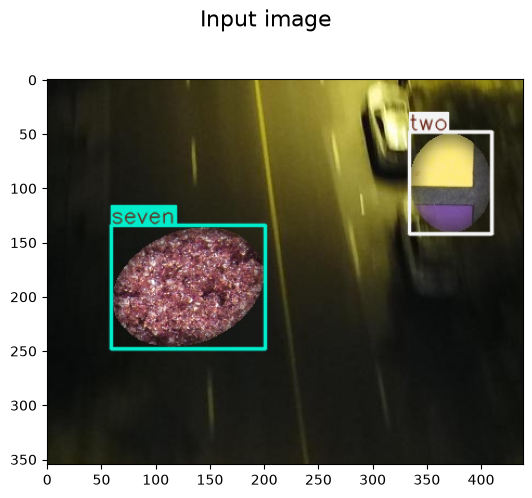

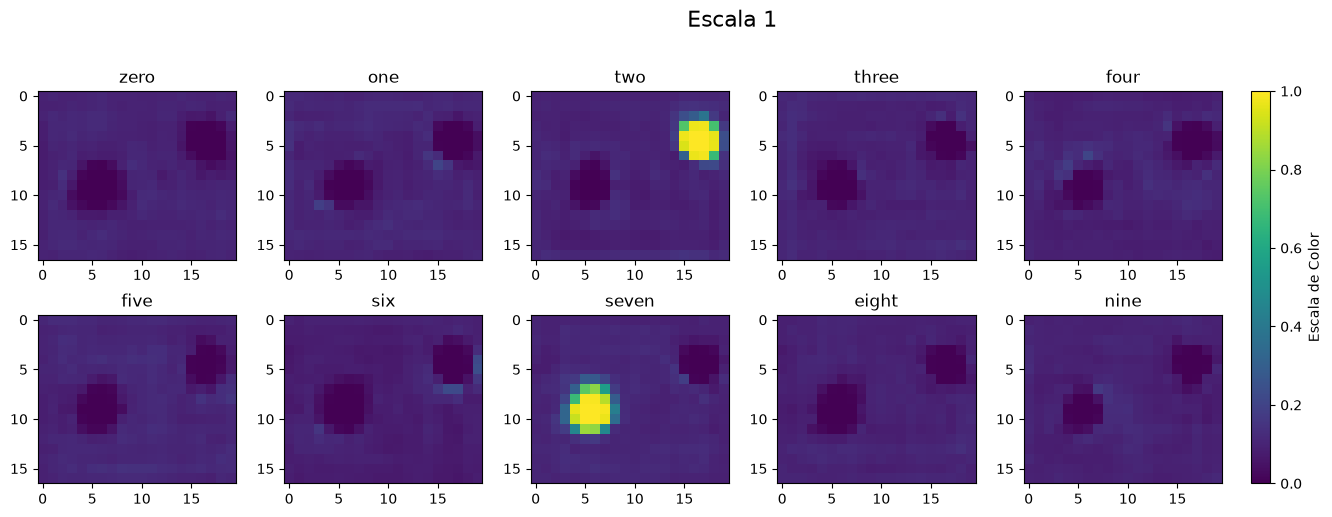

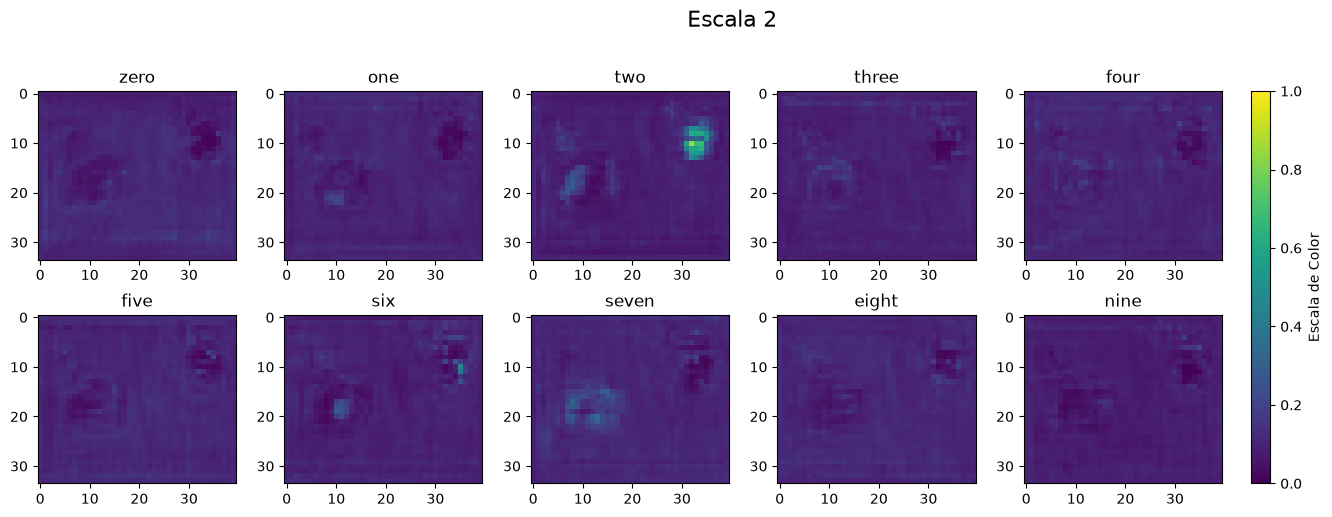

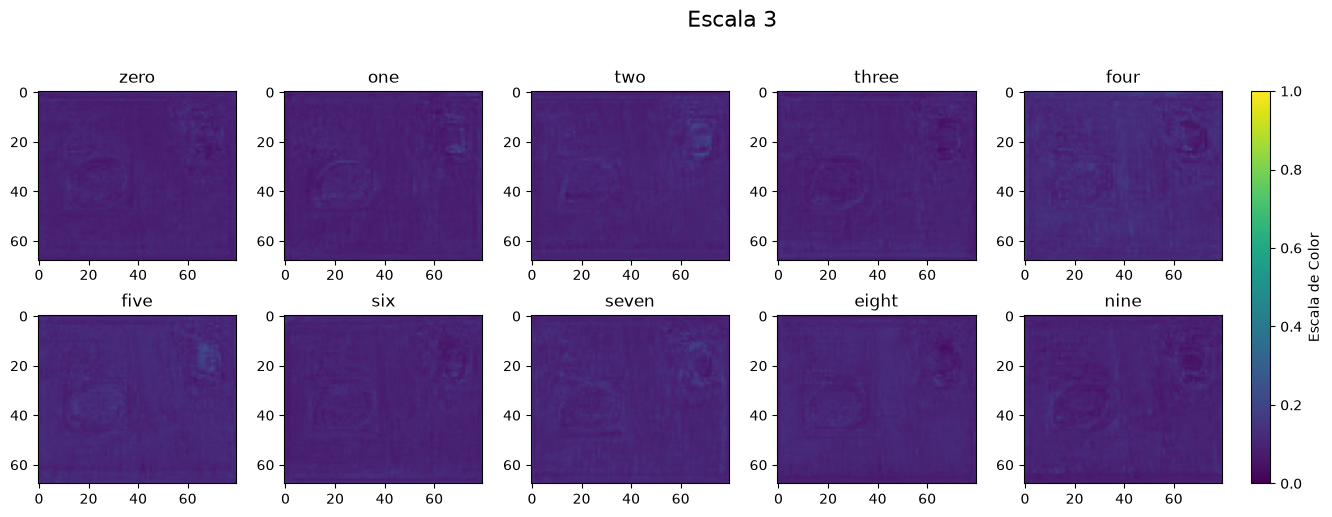

In [36]:
fig, axes = plt.subplots(1,1, figsize=(15,5))
fig.suptitle(f"Input image", fontsize=16, y=1.02)
axes.imshow(testimg)

for k in range(3):
  fig, axes = plt.subplots(2*1, 5, figsize=(15,5))
  fig.suptitle(f"Escala {k+1}", fontsize=16, y=1.02)
  tensor_to_plot = (scale1sm, scale2sm, scale3sm)[k]
  for i, ax in enumerate(axes.flat):
    im = ax.imshow(tensor_to_plot.cpu()[i,:,:].numpy(), cmap="viridis", vmin=0.0, vmax=1.0)
    ax.set_title(f"{model.names[i]}")
  fig.tight_layout()

  # Agregar una barra de color común para todos los subplots
  cbar = fig.colorbar(im, ax=axes.ravel().tolist(), orientation='vertical', pad=0.02)
  cbar.set_label('Escala de Color')
plt.show()

Para interpretar los _bounding boxes_, correctamente divididos también por escalas, tenemos que reformatear el cuarto tensor de salida, en el que vienen agregados. Usaremos para ello las dimensiones escaladas anteriores:

In [37]:
print(f"Dimensiones escala 1: {HS1}x{WS1}")
print(f"Dimensiones escala 2: {HS2}x{WS2}")
print(f"Dimensiones escala 3: {HS3}x{WS3}")
scale1boxes = fourth_output_tensor[0,:,HS3*WS3+HS2*WS2:].reshape(-1,HS1,WS1)
scale2boxes = fourth_output_tensor[0,:,HS3*WS3:HS3*WS3+HS2*WS2].reshape(-1,HS2,WS2)
scale3boxes = fourth_output_tensor[0,:,:HS3*WS3].reshape(-1,HS3,WS3)
print(f"Dimensiones tensor de cajas para escala 1: {scale1boxes.shape}")
print(f"Dimensiones tensor de cajas para escala 2: {scale2boxes.shape}")
print(f"Dimensiones tensor de cajas para escala 3: {scale3boxes.shape}")

Dimensiones escala 1: 17x20
Dimensiones escala 2: 34x40
Dimensiones escala 3: 68x80
Dimensiones tensor de cajas para escala 1: torch.Size([4, 17, 20])
Dimensiones tensor de cajas para escala 2: torch.Size([4, 34, 40])
Dimensiones tensor de cajas para escala 3: torch.Size([4, 68, 80])


En el caso de YOLOv8, cada vector de 4 elementos codifica las esquinas de una caja, siempre con valores positivos, y relativos al centro de la misma (dado por la posición `(row,col)` en el tensor). De modo que esta sencilla función `get_box_corners_from_pos` mapeará directamente dichos valores a las coordenadas de las esquinas superior izquierda (x1,y1) e inferior derecha (x2,y2) en los tensores correspondientes a cada escala:

In [38]:
def get_box_corners_from_pos(boxes_tensor, scale, row, col):
  tx1,ty1,tx2,ty2 = boxes_tensor[:,row,col]
  x1,y1,x2,y2 = float(col-tx1),float(row-ty1),float(col+tx2),float(row+ty2)
  return x1, y1, x2, y2

Finalmente, la siguiente función muestra, para todas aquellas posiciones en los tensores con valores superiores a un determinado umbral MIN_CONFIDENCE, las cajas propuestas (posiciones en el tensor marcadas con puntos, y cajas correspondientes dibujadas en el mismo, siempre usando el color de la clase correspondiente):

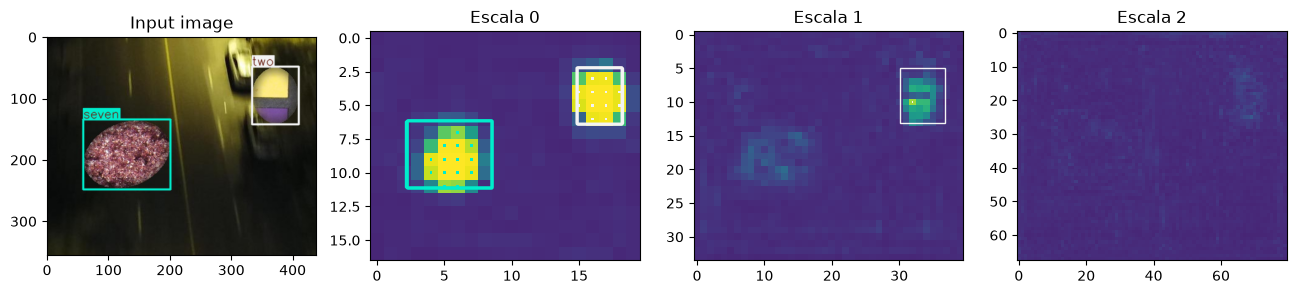

In [39]:
def plot_boxes_for_image(testimg, scale1sm, scale2sm, scale3sm, scale1boxes, scale2boxes, scale3boxes, MIN_CONFIDENCE):
  fig, axs = plt.subplots(1,4,figsize=(16,6))
  axs[0].set_title(f"Input image")
  axs[0].imshow(testimg)
  for k, (tensorclasses, tensorboxes) in enumerate(zip([scale1sm, scale2sm, scale3sm], [scale1boxes, scale2boxes, scale3boxes])):
    num_classes, rows, cols = tensorclasses.shape
    maxcl, indmaxcl = tensorclasses.max(dim=0)
    axs[k+1].imshow(maxcl.cpu().numpy(),vmin=0.0,vmax=1.0);
    axs[k+1].set_title(f"Escala {k}")
    for row in range(rows):
      for col in range(cols):
        if maxcl[row,col] > MIN_CONFIDENCE:
          x1,y1,x2,y2 = get_box_corners_from_pos(tensorboxes, 1, row, col)
          rect = mpatches.Rectangle((x1, y1), x2-x1, y2-y1, linewidth=1, edgecolor=np.array(colors(indmaxcl[row,col], True))/255, facecolor='none')
          axs[k+1].add_patch(rect)
          rect = mpatches.Rectangle((col-0.1, row-0.1), 0.2, 0.2, linewidth=0, edgecolor='none', facecolor=np.array(colors(indmaxcl[row,col], True))/255)
          axs[k+1].add_patch(rect)

plot_boxes_for_image(testimg, scale1sm, scale2sm, scale3sm, scale1boxes, scale2boxes, scale3boxes, MIN_CONFIDENCE=0.75)

Habitualmente, los detectores de objetos implementan después una sencilla función de postprocesamiento, que suele denominarse `non_maxima_suppression` (NMS), que unifica cada _"cluster"_ de bounding_boxes en adecuadas cajas individuales. Esto es exactamente lo que implementa la librería ultralytics en su función de inferencia de alto nivel, que, como hemos visto, devuelve una sola caja por objeto en la correspondiente variable devuelta `results`.

# Apéndice: Introspección en modelos YOLOV4

En realidad, un modelo YOLOV4 hereda de un modelo Pytorch, al que simplemente añade ciertas funcionalidades adicionales:

In [40]:
def get_class_hierarchy(obj):
    """
    Esta función recibe un objeto y retorna una lista con su jerarquía de clases,
    comenzando por su clase inmediata y siguiendo hacia arriba hasta object.
    """
    jerarquia = []
    # Obtener la clase del objeto:
    clase_actual = type(obj)

    while clase_actual:
        # Añadir la clase actual a la lista de jerarquía:
        jerarquia.append(clase_actual)
        # Si llegamos a la clase base 'object', detener el bucle:
        if clase_actual == object:
            break
        # Obtener la siguiente clase base (nota: esto solo toma la primera clase base;
        # en Python, una clase puede heredar de múltiples clases).
        clase_actual = clase_actual.__bases__[0]

    return jerarquia

print(f"Jerarquía de clases de la clase de 'model': \n {get_class_hierarchy(model)}")
print(f"Jerarquía de clases de una de las capas finales de 'model': \n {get_class_hierarchy(model.model.model[22].dfl)}")
print(f"Acceso a los nombres de todos los submódulos (capas, con relación jerárquica de inclusión entre ellas) del modelo:")
for name, module in model.named_modules():
   print(name)

Jerarquía de clases de la clase de 'model': 
 [<class 'ultralytics.models.yolo.model.YOLO'>, <class 'ultralytics.engine.model.Model'>, <class 'torch.nn.modules.module.Module'>, <class 'object'>]
Jerarquía de clases de una de las capas finales de 'model': 
 [<class 'ultralytics.nn.modules.block.DFL'>, <class 'torch.nn.modules.module.Module'>, <class 'object'>]
Acceso a los nombres de todos los submódulos (capas, con relación jerárquica de inclusión entre ellas) del modelo:

model
model.model
model.model.0
model.model.0.conv
model.model.0.bn
model.model.0.act
model.model.1
model.model.1.conv
model.model.1.bn
model.model.2
model.model.2.cv1
model.model.2.cv1.conv
model.model.2.cv1.bn
model.model.2.cv2
model.model.2.cv2.conv
model.model.2.cv2.bn
model.model.2.m
model.model.2.m.0
model.model.2.m.0.cv1
model.model.2.m.0.cv1.conv
model.model.2.m.0.cv1.bn
model.model.2.m.0.cv2
model.model.2.m.0.cv2.conv
model.model.2.m.0.cv2.bn
model.model.3
model.model.3.conv
model.model.3.bn
model.model.4
mo

In [41]:
!date # Para medir el tiempo de ejecución de todo el notebook

mar 17 nov 2026 16:50:02 CET
